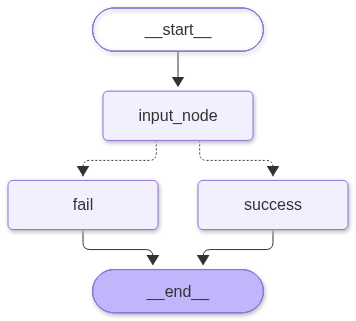

In [1]:

from typing import TypedDict, Literal

from IPython.core.display import Image
from langgraph.constants import START, END
from langgraph.graph import StateGraph
from langgraph.types import Command


# State
class ConditionalState(TypedDict):
    score: int
    message: str


# Node
def input_node(state: ConditionalState) -> Command[Literal["success", "fail"]]:
    _input = int(input("请输入分数"))

    goto = "success"

    if (_input < 60):
        goto = "fail"

    return Command(
        update={"score": int(_input)},
        goto=goto
    )


def success_node(state: ConditionalState):
    return {"message": "通过"}


def fail_node(state: ConditionalState):
    return {"message": "不通过"}


# Edge
builder = StateGraph(ConditionalState)

builder.add_node("input_node", input_node)
builder.add_node("success", success_node)
builder.add_node("fail", fail_node)

builder.add_edge(START, "input_node")
builder.add_edge("success", END)
builder.add_edge("fail", END)

graph = builder.compile()

display(Image(graph.get_graph(xray=True).draw_mermaid_png()))

In [3]:
res_state = graph.invoke({})
print(f"res_state = {res_state}")

res_state = {'score': 89, 'message': '通过'}
